In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
def mse(y_true, y_pred):
    return np.mean((y_pred - y_true) ** 2)

In [17]:
def batch_gradient_descent(X, y, learning_rate=0.01, epochs=1000):

    n_samples, n_features = X.shape

    weights = np.zeros(n_features)
    bias = 0

    cost_history = []

    for epoch in range(epochs):

        y_pred = X @ weights + bias
        error = y_pred - y

        dw = (2 / n_samples) * (X.T @ error)
        db = (2 / n_samples) * np.sum(error)

        weights -= learning_rate * dw
        bias -= learning_rate * db

        cost = mse(y, y_pred)
        cost_history.append(cost)

    return weights, bias, cost_history

In [ ]:
def stochastic_gradient_descent(X, y, learning_rate=0.01, epochs=1000):

    n_samples, n_features = X.shape

    weights = np.zeros(n_features)
    bias = 0

    cost_history = []

    for epoch in range(epochs):

        indices = np.arange(n_samples)
        np.random.shuffle(indices)

        for i in indices:

            xi = X[i]
            yi = y[i]

            y_pred = np.dot(xi, weights) + bias
            error = y_pred - yi

            dw = 2 * xi * error
            db = 2 * error

            weights -= learning_rate * dw
            bias -= learning_rate * db

        predictions = X @ weights + bias
        cost = mse(y, predictions)
        cost_history.append(cost)

    return weights, bias, cost_history

In [ ]:
def mini_batch_gradient_descent(
    X,
    y,
    learning_rate=0.01,
    epochs=1000,
    batch_size=32
):

    n_samples, n_features = X.shape

    weights = np.zeros(n_features)
    bias = 0

    cost_history = []

    for epoch in range(epochs):

        indices = np.arange(n_samples)
        np.random.shuffle(indices)

        X_shuffled = X[indices]
        y_shuffled = y[indices]

        for start in range(0, n_samples, batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            y_pred = X_batch @ weights + bias
            error = y_pred - y_batch

            dw = (2 / len(X_batch)) * (X_batch.T @ error)
            db = (2 / len(X_batch)) * np.sum(error)

            weights -= learning_rate * dw
            bias -= learning_rate * db

        predictions = X @ weights + bias
        cost = mse(y, predictions)
        cost_history.append(cost)

    return weights, bias, cost_history

FOR DATASET 1

In [8]:
import pandas as pd

df1 = pd.read_csv("insurance.csv")

print(df1.head())
print("\nShape:", df1.shape)
print("\nColumns:")
print(df1.columns)
print("\nData types:")
print(df1.dtypes)
print("\nMissing values:")
print(df1.isnull().sum())

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520

Shape: (1338, 7)

Columns:
Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')

Data types:
age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

Missing values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [9]:
X1 = df1.drop("charges", axis=1)
y1 = df1["charges"]

print("Features shape:", X1.shape)
print("Target shape:", y1.shape)

Features shape: (1338, 6)
Target shape: (1338,)


In [10]:
categorical_cols = X1.select_dtypes(exclude=np.number).columns
numerical_cols = X1.select_dtypes(include=np.number).columns

X1[numerical_cols] = X1[numerical_cols].fillna(
    X1[numerical_cols].median()
)

X1[categorical_cols] = X1[categorical_cols].fillna(
    X1[categorical_cols].mode().iloc[0]
)

X1 = pd.get_dummies(
    X1,
    columns=categorical_cols,
    drop_first=True
)

print("Shape after encoding:", X1.shape)
print("Missing values:", X1.isnull().sum().sum())

Shape after encoding: (1338, 8)
Missing values: 0


In [12]:
X1 = X1.astype(float).values
y1 = y1.astype(float).values

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1,
    y1,
    test_size=0.2,
    random_state=42
)

print("Training data:", X1_train.shape)
print("Testing data:", X1_test.shape)

Training data: (1070, 8)
Testing data: (268, 8)


In [13]:
scaler1 = StandardScaler()

X1_train = scaler1.fit_transform(X1_train)
X1_test = scaler1.transform(X1_test)

y_scaler1 = StandardScaler()

y1_train_scaled = y_scaler1.fit_transform(
    y1_train.reshape(-1, 1)
).ravel()

y1_test_scaled = y_scaler1.transform(
    y1_test.reshape(-1, 1)
).ravel()

print("First 5 scaled target values:")
print(y1_train_scaled[:5])

First 5 scaled target values:
[-0.3456208  -0.40048783  1.14633152 -0.39531416 -0.07247763]


In [19]:
weights_bgd1, bias_bgd1, cost_bgd1 = batch_gradient_descent(
    X1_train,
    y1_train_scaled,
    learning_rate=0.01,
    epochs=1000
)

print("Batch GD completed")
print("Final Training MSE:", cost_bgd1[-1])

Batch GD completed
Final Training MSE: 0.25827441701537723


In [20]:
weights_sgd1, bias_sgd1, cost_sgd1 = stochastic_gradient_descent(
    X1_train,
    y1_train_scaled,
    learning_rate=0.001,
    epochs=1000
)

print("Stochastic GD completed")
print("Final Training MSE:", cost_sgd1[-1])

Stochastic GD completed
Final Training MSE: 0.25863226040599074


In [21]:
weights_mbgd1, bias_mbgd1, cost_mbgd1 = mini_batch_gradient_descent(
    X1_train,
    y1_train_scaled,
    learning_rate=0.001,
    epochs=1000,
    batch_size=32
)

print("Mini-Batch GD completed")
print("Final Training MSE:", cost_mbgd1[-1])

Mini-Batch GD completed
Final Training MSE: 0.2582763206650017


In [22]:
y_pred_bgd1 = X1_test @ weights_bgd1 + bias_bgd1
y_pred_sgd1 = X1_test @ weights_sgd1 + bias_sgd1
y_pred_mbgd1 = X1_test @ weights_mbgd1 + bias_mbgd1

mse_bgd1 = mse(y1_test_scaled, y_pred_bgd1)
mse_sgd1 = mse(y1_test_scaled, y_pred_sgd1)
mse_mbgd1 = mse(y1_test_scaled, y_pred_mbgd1)

print("Test MSE - Insurance Dataset")
print("Batch GD:", mse_bgd1)
print("Stochastic GD:", mse_sgd1)
print("Mini-Batch GD:", mse_mbgd1)

Test MSE - Insurance Dataset
Batch GD: 0.2327756835810776
Stochastic GD: 0.23340802399680793
Mini-Batch GD: 0.23279008074511143


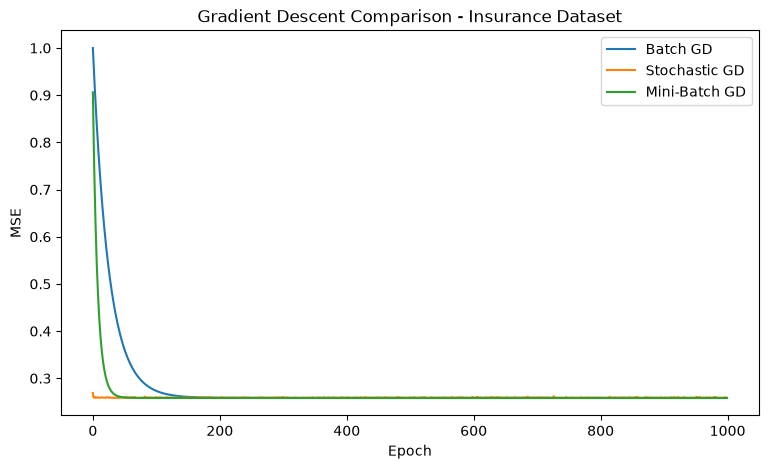

In [23]:
plt.figure(figsize=(9, 5))

plt.plot(cost_bgd1, label="Batch GD")
plt.plot(cost_sgd1, label="Stochastic GD")
plt.plot(cost_mbgd1, label="Mini-Batch GD")

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Gradient Descent Comparison - Insurance Dataset")
plt.legend()

plt.show()

In [55]:
X_contour = df1[["age", "bmi"]].values
y_contour = df1["charges"].values

print("X shape:", X_contour.shape)
print("y shape:", y_contour.shape)

X shape: (1338, 2)
y shape: (1338,)


In [56]:
x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_contour = x_scaler.fit_transform(X_contour)
y_contour = y_scaler.fit_transform(
    y_contour.reshape(-1, 1)
).ravel()

print(X_contour[:5])
print(y_contour[:5])

[[-1.43876426 -0.45332   ]
 [-1.50996545  0.5096211 ]
 [-0.79795355  0.38330685]
 [-0.4419476  -1.30553108]
 [-0.51314879 -0.29255641]]
[ 0.2985838  -0.95368917 -0.72867467  0.71984298 -0.77680218]


In [57]:
w1 = np.linspace(-2, 2, 100)
w2 = np.linspace(-2, 2, 100)

W1, W2 = np.meshgrid(w1, w2)

cost = np.zeros(W1.shape)

for i in range(W1.shape[0]):
    for j in range(W1.shape[1]):

        predictions = (
            X_contour[:, 0] * W1[i, j]
            + X_contour[:, 1] * W2[i, j]
        )

        cost[i, j] = mse(y_contour, predictions)

print("Cost shape:", cost.shape)

Cost shape: (100, 100)


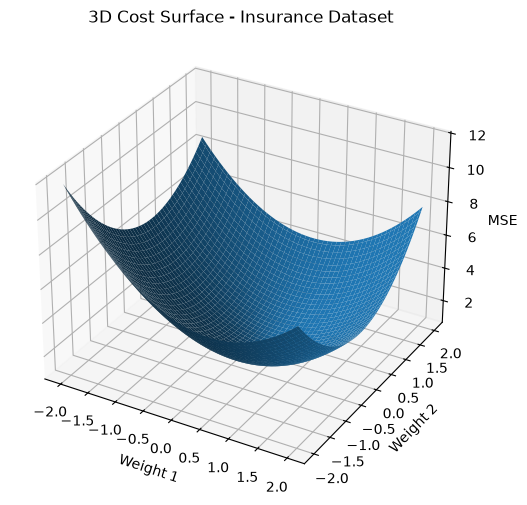

In [58]:
fig = plt.figure(figsize=(9, 6))

ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(W1, W2, cost)

ax.set_xlabel("Weight 1")
ax.set_ylabel("Weight 2")
ax.set_zlabel("MSE")

ax.set_title("3D Cost Surface - Insurance Dataset")

plt.show()

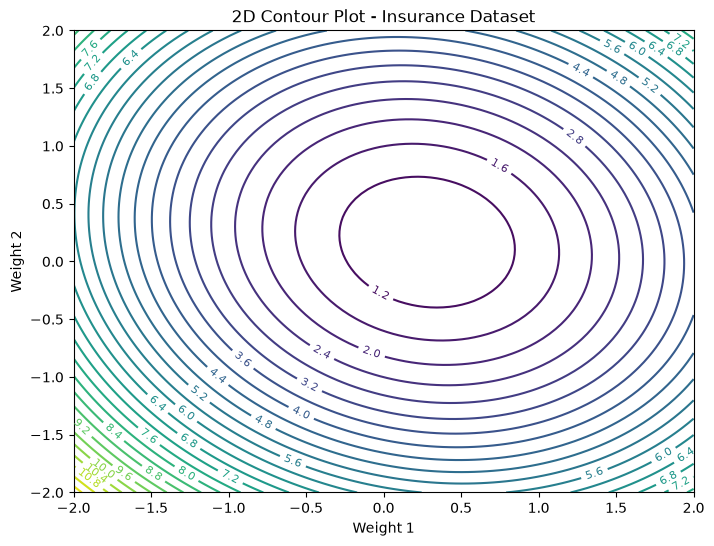

In [59]:
plt.figure(figsize=(8, 6))

contour = plt.contour(W1, W2, cost, levels=30)

plt.clabel(contour, inline=True, fontsize=8)

plt.xlabel("Weight 1")
plt.ylabel("Weight 2")

plt.title("2D Contour Plot - Insurance Dataset")

plt.show()

In [60]:
weights_contour, bias_contour, cost_contour = batch_gradient_descent(
    X_contour,
    y_contour,
    learning_rate=0.01,
    epochs=1000
)

print("Weights:", weights_contour)
print("Bias:", bias_contour)
print("Final MSE:", cost_contour[-1])

Weights: [0.2806866  0.16766982]
Bias: 1.3913467621012417e-17
Final MSE: 0.8828166139306006


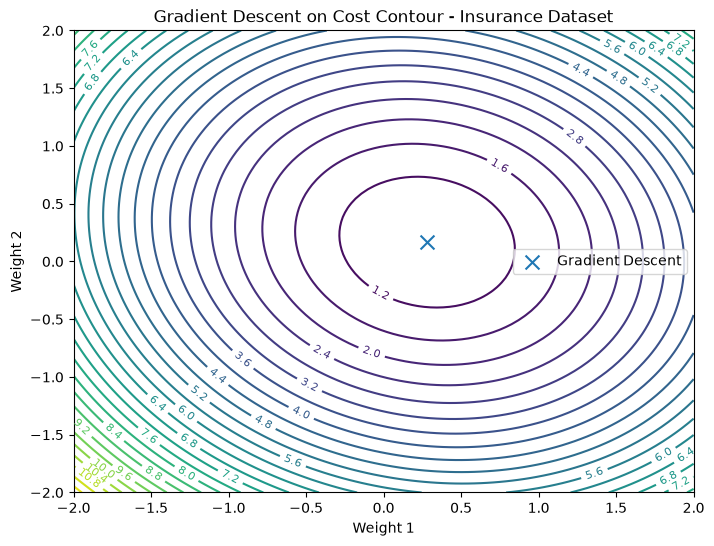

In [61]:
plt.figure(figsize=(8, 6))

contour = plt.contour(W1, W2, cost, levels=30)

plt.clabel(contour, inline=True, fontsize=8)

plt.scatter(
    weights_contour[0],
    weights_contour[1],
    s=100,
    marker="x",
    label="Gradient Descent"
)

plt.xlabel("Weight 1")
plt.ylabel("Weight 2")

plt.title("Gradient Descent on Cost Contour - Insurance Dataset")

plt.legend()

plt.show()

FOR DATASET 2

In [24]:
df2 = pd.read_csv("train.csv")

print(df2.head())

print("\nShape:")
print(df2.shape)

print("\nColumns:")
print(df2.columns)

print("\nData types:")
print(df2.dtypes)

print("\nMissing values:")
print(df2.isnull().sum())

   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCondition  SalePrice  
0   2008        WD   

In [25]:
df2 = df2.drop("Id", axis=1)

X2 = df2.drop("SalePrice", axis=1)
y2 = df2["SalePrice"]

print("Features shape:", X2.shape)
print("Target shape:", y2.shape)

Features shape: (1460, 79)
Target shape: (1460,)


In [26]:
numerical_cols = X2.select_dtypes(include=np.number).columns
categorical_cols = X2.select_dtypes(exclude=np.number).columns

print("Numerical columns:", len(numerical_cols))
print("Categorical columns:", len(categorical_cols))

Numerical columns: 36
Categorical columns: 43


In [27]:
X2[numerical_cols] = X2[numerical_cols].fillna(
    X2[numerical_cols].median()
)

X2[categorical_cols] = X2[categorical_cols].fillna(
    X2[categorical_cols].mode().iloc[0]
)

print("Missing values after preprocessing:")
print(X2.isnull().sum().sum())

Missing values after preprocessing:
0


In [28]:
X2 = pd.get_dummies(
    X2,
    columns=categorical_cols,
    drop_first=True
)

print("Shape after encoding:", X2.shape)

Shape after encoding: (1460, 244)


In [29]:
X2 = X2.astype(float).values
y2 = y2.astype(float).values

print("X2 shape:", X2.shape)
print("y2 shape:", y2.shape)

X2 shape: (1460, 244)
y2 shape: (1460,)


In [30]:
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2,
    y2,
    test_size=0.2,
    random_state=42
)

print("Training data:", X2_train.shape)
print("Testing data:", X2_test.shape)

Training data: (1168, 244)
Testing data: (292, 244)


In [31]:
scaler2 = StandardScaler()

X2_train = scaler2.fit_transform(X2_train)
X2_test = scaler2.transform(X2_test)

y_scaler2 = StandardScaler()

y2_train_scaled = y_scaler2.fit_transform(
    y2_train.reshape(-1, 1)
).ravel()

y2_test_scaled = y_scaler2.transform(
    y2_test.reshape(-1, 1)
).ravel()

print("First 5 rows of X2_train:")
print(X2_train[:5])

print("\nFirst 5 scaled target values:")
print(y2_train_scaled[:5])

First 5 rows of X2_train:
[[-0.8667643  -0.00419319 -0.21289571 ... -0.12510865  0.46001984
  -0.30263639]
 [ 0.07410996 -0.49395768 -0.26524463 ... -0.12510865  0.46001984
  -0.30263639]
 [-0.63154574 -0.13776532 -0.17784146 ... -0.12510865  0.46001984
  -0.30263639]
 [-0.16110861 -0.44943363 -0.32447422 ... -0.12510865  0.46001984
  -0.30263639]
 [-0.16110861 -0.89467408 -0.52903482 ... -0.12510865  0.46001984
  -0.30263639]]

First 5 scaled target values:
[-0.47185427 -0.04456195 -1.24874939 -0.08340671 -0.70492281]


In [32]:
weights_bgd2, bias_bgd2, cost_bgd2 = batch_gradient_descent(
    X2_train,
    y2_train_scaled,
    learning_rate=0.01,
    epochs=1000
)

print("Batch GD completed")
print("Final Training MSE:", cost_bgd2[-1])

Batch GD completed
Final Training MSE: 0.08009341338217034


In [34]:
weights_sgd2, bias_sgd2, cost_sgd2 = stochastic_gradient_descent(
    X2_train,
    y2_train_scaled,
    learning_rate=0.0001,
    epochs=1000
)

print("Stochastic GD completed")
print("Final Training MSE:", cost_sgd2[-1])

Stochastic GD completed
Final Training MSE: 0.0651549068889452


In [35]:
weights_mbgd2, bias_mbgd2, cost_mbgd2 = mini_batch_gradient_descent(
    X2_train,
    y2_train_scaled,
    learning_rate=0.001,
    epochs=1000,
    batch_size=32
)

print("Mini-Batch GD completed")
print("Final Training MSE:", cost_mbgd2[-1])

Mini-Batch GD completed
Final Training MSE: 0.07083423911894624


In [36]:
y_pred_bgd2 = X2_test @ weights_bgd2 + bias_bgd2
y_pred_sgd2 = X2_test @ weights_sgd2 + bias_sgd2
y_pred_mbgd2 = X2_test @ weights_mbgd2 + bias_mbgd2

mse_bgd2 = mse(y2_test_scaled, y_pred_bgd2)
mse_sgd2 = mse(y2_test_scaled, y_pred_sgd2)
mse_mbgd2 = mse(y2_test_scaled, y_pred_mbgd2)

print("Test MSE - House Prices Dataset")
print("Batch GD:", mse_bgd2)
print("Stochastic GD:", mse_sgd2)
print("Mini-Batch GD:", mse_mbgd2)

Test MSE - House Prices Dataset
Batch GD: 0.16780548986600435
Stochastic GD: 0.3550978121487289
Mini-Batch GD: 0.21875748400249181


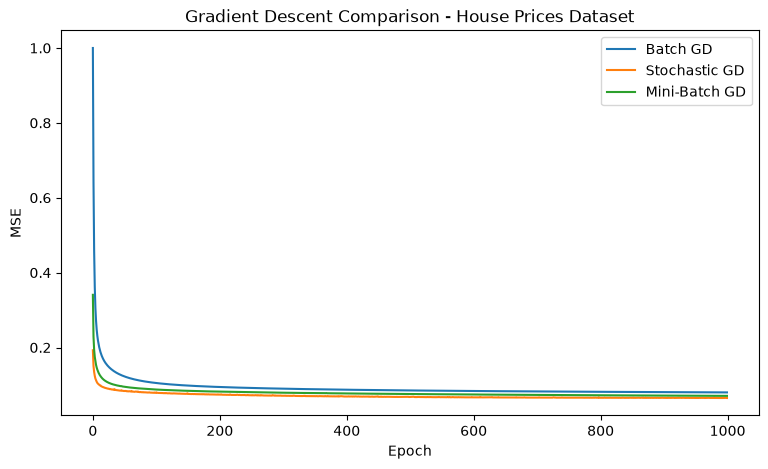

In [37]:
plt.figure(figsize=(9, 5))

plt.plot(cost_bgd2, label="Batch GD")
plt.plot(cost_sgd2, label="Stochastic GD")
plt.plot(cost_mbgd2, label="Mini-Batch GD")

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Gradient Descent Comparison - House Prices Dataset")
plt.legend()

plt.show()

In [62]:
X_contour2 = df2[["OverallQual", "GrLivArea"]].values
y_contour2 = df2["SalePrice"].values

print("Contour features shape:", X_contour2.shape)
print("Target shape:", y_contour2.shape)

Contour features shape: (1460, 2)
Target shape: (1460,)


In [63]:
from sklearn.preprocessing import StandardScaler

x_scaler2 = StandardScaler()
y_scaler_contour2 = StandardScaler()

X_contour2 = x_scaler2.fit_transform(X_contour2)
y_contour2 = y_scaler_contour2.fit_transform(
    y_contour2.reshape(-1, 1)
).ravel()

print("First 5 X values:")
print(X_contour2[:5])

print("\nFirst 5 y values:")
print(y_contour2[:5])

First 5 X values:
[[ 0.65147924  0.37033344]
 [-0.07183611 -0.48251191]
 [ 0.65147924  0.51501256]
 [ 0.65147924  0.38365915]
 [ 1.3747946   1.2993257 ]]

First 5 y values:
[ 0.34727322  0.00728832  0.53615372 -0.51528106  0.8698426 ]


In [64]:
def contour_cost2(w1, w2, bias):
    predictions = (
        w1 * X_contour2[:, 0] +
        w2 * X_contour2[:, 1] +
        bias
    )
    
    return np.mean((predictions - y_contour2) ** 2)

In [65]:
w1_values = np.linspace(-2, 2, 100)
w2_values = np.linspace(-2, 2, 100)

W1, W2 = np.meshgrid(w1_values, w2_values)

Z = np.zeros(W1.shape)

for i in range(W1.shape[0]):
    for j in range(W1.shape[1]):
        Z[i, j] = contour_cost2(W1[i, j], W2[i, j], 0)

print("Cost surface created.")

Cost surface created.


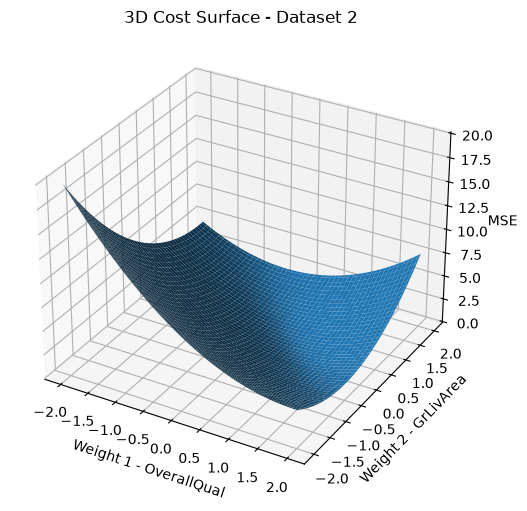

In [66]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(9, 6))

ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(W1, W2, Z)

ax.set_xlabel("Weight 1 - OverallQual")
ax.set_ylabel("Weight 2 - GrLivArea")
ax.set_zlabel("MSE")

ax.set_title("3D Cost Surface - Dataset 2")

plt.show()

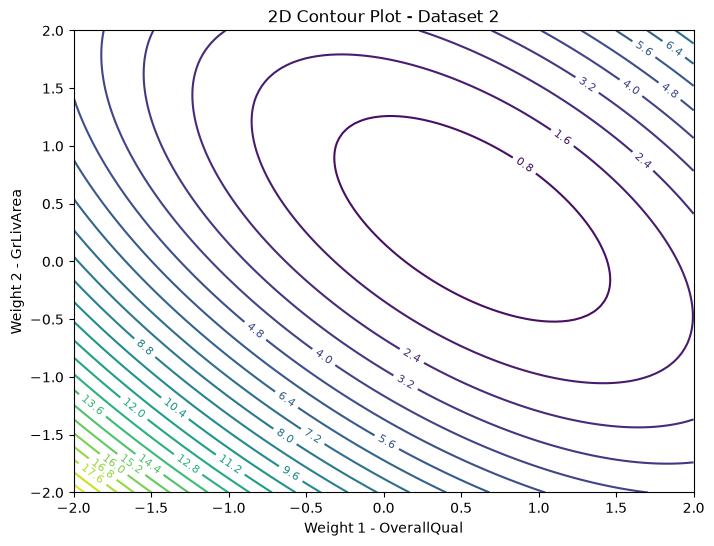

In [67]:
plt.figure(figsize=(8, 6))

contour = plt.contour(W1, W2, Z, levels=30)

plt.clabel(contour, inline=True, fontsize=8)

plt.xlabel("Weight 1 - OverallQual")
plt.ylabel("Weight 2 - GrLivArea")

plt.title("2D Contour Plot - Dataset 2")

plt.show()

In [68]:
min_index = np.unravel_index(np.argmin(Z), Z.shape)

best_w1 = W1[min_index]
best_w2 = W2[min_index]

print("Minimum cost point:")
print("Weight 1:", best_w1)
print("Weight 2:", best_w2)
print("Minimum MSE:", Z[min_index])

Minimum cost point:
Weight 1: 0.5858585858585861
Weight 2: 0.3434343434343434
Minimum MSE: 0.2862696275523116


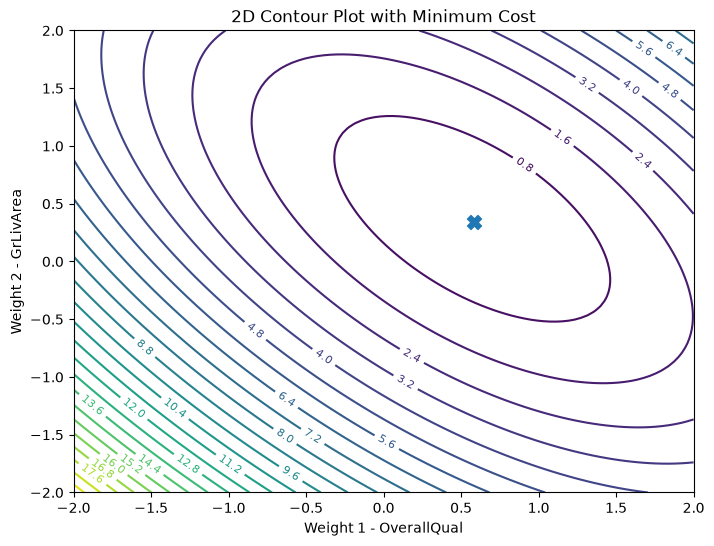

In [69]:
plt.figure(figsize=(8, 6))

contour = plt.contour(W1, W2, Z, levels=30)

plt.clabel(contour, inline=True, fontsize=8)

plt.scatter(best_w1, best_w2, marker="X", s=100)

plt.xlabel("Weight 1 - OverallQual")
plt.ylabel("Weight 2 - GrLivArea")

plt.title("2D Contour Plot with Minimum Cost")

plt.show()

FOR DATASET 3

In [42]:
df3 = pd.read_csv("winequality-red.csv", sep=",")

print(df3.head())

print("\nShape:")
print(df3.shape)

print("\nColumns:")
print(df3.columns)

print("\nData types:")
print(df3.dtypes)

print("\nMissing values:")
print(df3.isnull().sum())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2      9.8        5 

In [43]:
X3 = df3.drop("quality", axis=1)
y3 = df3["quality"]

print("Features shape:", X3.shape)
print("Target shape:", y3.shape)

Features shape: (1599, 11)
Target shape: (1599,)


In [44]:
X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3,
    y3,
    test_size=0.2,
    random_state=42
)

print("Training data:", X3_train.shape)
print("Testing data:", X3_test.shape)

Training data: (1279, 11)
Testing data: (320, 11)


In [45]:
scaler3 = StandardScaler()

X3_train = scaler3.fit_transform(X3_train)
X3_test = scaler3.transform(X3_test)

y_scaler3 = StandardScaler()

y3_train_scaled = y_scaler3.fit_transform(
    y3_train.values.reshape(-1, 1)
).ravel()

y3_test_scaled = y_scaler3.transform(
    y3_test.values.reshape(-1, 1)
).ravel()

print("First 5 scaled target values:")
print(y3_train_scaled[:5])

First 5 scaled target values:
[ 0.46625122  0.46625122  0.46625122 -0.77353113 -0.77353113]


In [46]:
weights_bgd3, bias_bgd3, cost_bgd3 = batch_gradient_descent(
    X3_train,
    y3_train_scaled,
    learning_rate=0.01,
    epochs=1000
)

print("Batch GD Final Training MSE:", cost_bgd3[-1])

Batch GD Final Training MSE: 0.6520586883257954


In [47]:
weights_sgd3, bias_sgd3, cost_sgd3 = stochastic_gradient_descent(
    X3_train,
    y3_train_scaled,
    learning_rate=0.001,
    epochs=1000
)

print("Stochastic GD Final Training MSE:", cost_sgd3[-1])

Stochastic GD Final Training MSE: 0.6560534810122794


In [48]:
weights_mbgd3, bias_mbgd3, cost_mbgd3 = mini_batch_gradient_descent(
    X3_train,
    y3_train_scaled,
    learning_rate=0.01,
    epochs=1000,
    batch_size=32
)

print("Mini-Batch GD Final Training MSE:", cost_mbgd3[-1])

Mini-Batch GD Final Training MSE: 0.6521037853837245


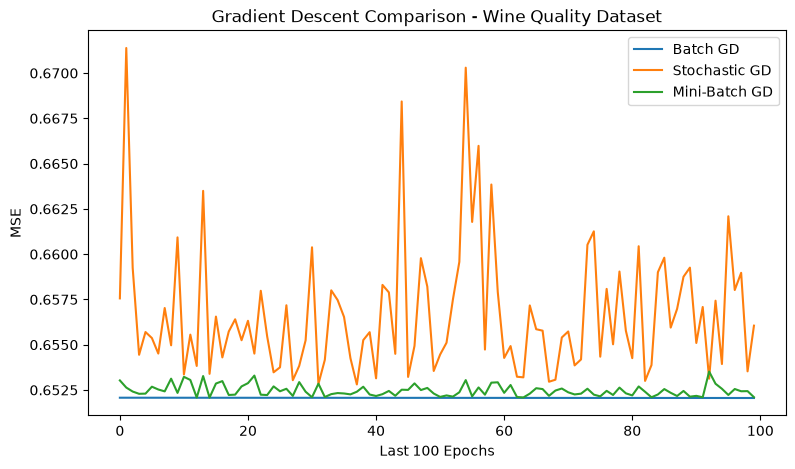

In [50]:
plt.figure(figsize=(9, 5))

plt.plot(cost_bgd3[-100:], label="Batch GD")
plt.plot(cost_sgd3[-100:], label="Stochastic GD")
plt.plot(cost_mbgd3[-100:], label="Mini-Batch GD")

plt.xlabel("Last 100 Epochs")
plt.ylabel("MSE")
plt.title("Gradient Descent Comparison - Wine Quality Dataset")
plt.legend()

plt.show()

In [51]:
y_pred_bgd3 = X3_test @ weights_bgd3 + bias_bgd3
y_pred_sgd3 = X3_test @ weights_sgd3 + bias_sgd3
y_pred_mbgd3 = X3_test @ weights_mbgd3 + bias_mbgd3

mse_bgd3 = mse(y3_test_scaled, y_pred_bgd3)
mse_sgd3 = mse(y3_test_scaled, y_pred_sgd3)
mse_mbgd3 = mse(y3_test_scaled, y_pred_mbgd3)

print("Test MSE - Wine Quality Dataset")
print("Batch GD:", mse_bgd3)
print("Stochastic GD:", mse_sgd3)
print("Mini-Batch GD:", mse_mbgd3)

Test MSE - Wine Quality Dataset
Batch GD: 0.5992058588890092
Stochastic GD: 0.5991205271539213
Mini-Batch GD: 0.59989641547457


In [52]:
results3 = {
    "Batch GD": mse_bgd3,
    "Stochastic GD": mse_sgd3,
    "Mini-Batch GD": mse_mbgd3
}

best_method3 = min(results3, key=results3.get)

print("Best Gradient Descent method:", best_method3)
print("Lowest Test MSE:", results3[best_method3])

Best Gradient Descent method: Stochastic GD
Lowest Test MSE: 0.5991205271539213


In [70]:
X_contour3 = df3[["alcohol", "volatile acidity"]].values
y_contour3 = df3["quality"].values

print("Contour features shape:", X_contour3.shape)
print("Target shape:", y_contour3.shape)

Contour features shape: (1599, 2)
Target shape: (1599,)


In [71]:
x_scaler3 = StandardScaler()
y_scaler_contour3 = StandardScaler()

X_contour3 = x_scaler3.fit_transform(X_contour3)

y_contour3 = y_scaler_contour3.fit_transform(
    y_contour3.reshape(-1, 1)
).ravel()

print("First 5 scaled feature values:")
print(X_contour3[:5])

print("\nFirst 5 scaled target values:")
print(y_contour3[:5])

First 5 scaled feature values:
[[-0.96024611  0.96187667]
 [-0.58477711  1.96744245]
 [-0.58477711  1.29706527]
 [-0.58477711 -1.38444349]
 [-0.96024611  0.96187667]]

First 5 scaled target values:
[-0.78782264 -0.78782264 -0.78782264  0.45084835 -0.78782264]


In [72]:
def contour_cost3(w1, w2, bias):
    predictions = (
        w1 * X_contour3[:, 0] +
        w2 * X_contour3[:, 1] +
        bias
    )
    
    return np.mean((predictions - y_contour3) ** 2)

In [73]:
w1_values = np.linspace(-2, 2, 100)
w2_values = np.linspace(-2, 2, 100)

W1, W2 = np.meshgrid(w1_values, w2_values)

Z = np.zeros(W1.shape)

for i in range(W1.shape[0]):
    for j in range(W1.shape[1]):
        Z[i, j] = contour_cost3(W1[i, j], W2[i, j], 0)

print("Cost surface created.")

Cost surface created.


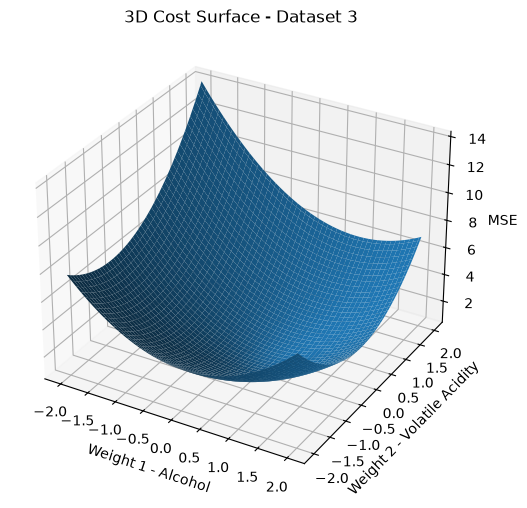

In [74]:
fig = plt.figure(figsize=(9, 6))

ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(W1, W2, Z)

ax.set_xlabel("Weight 1 - Alcohol")
ax.set_ylabel("Weight 2 - Volatile Acidity")
ax.set_zlabel("MSE")

ax.set_title("3D Cost Surface - Dataset 3")

plt.show()

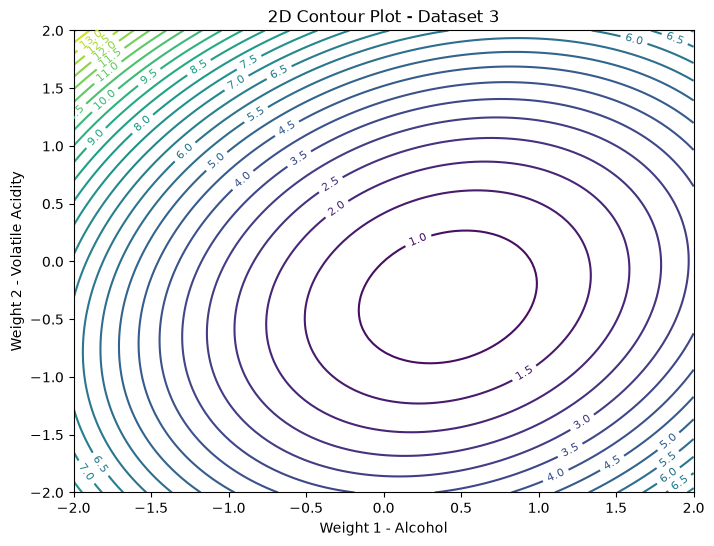

In [75]:
plt.figure(figsize=(8, 6))

contour = plt.contour(W1, W2, Z, levels=30)

plt.clabel(contour, inline=True, fontsize=8)

plt.xlabel("Weight 1 - Alcohol")
plt.ylabel("Weight 2 - Volatile Acidity")

plt.title("2D Contour Plot - Dataset 3")

plt.show()

In [76]:
min_index = np.unravel_index(np.argmin(Z), Z.shape)

best_w1 = W1[min_index]
best_w2 = W2[min_index]

print("Minimum cost point:")
print("Weight 1:", best_w1)
print("Weight 2:", best_w2)
print("Minimum MSE:", Z[min_index])

Minimum cost point:
Weight 1: 0.4242424242424243
Weight 2: -0.303030303030303
Minimum MSE: 0.6830990167599793


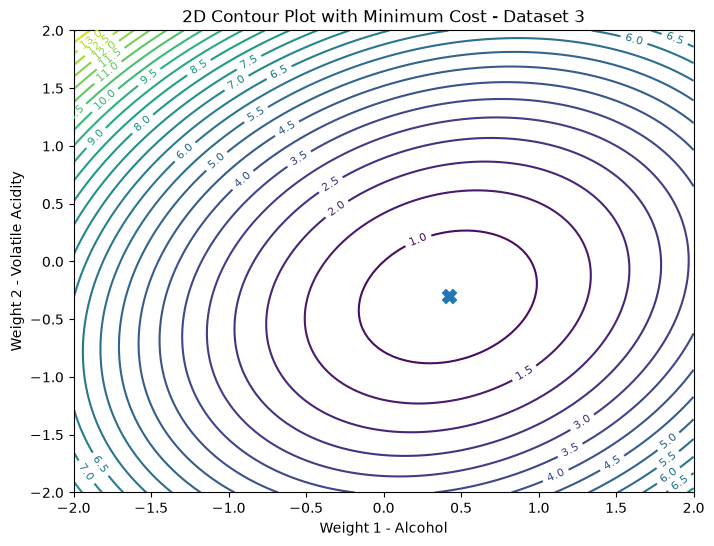

In [77]:
plt.figure(figsize=(8, 6))

contour = plt.contour(W1, W2, Z, levels=30)

plt.clabel(contour, inline=True, fontsize=8)

plt.scatter(best_w1, best_w2, marker="X", s=100)

plt.xlabel("Weight 1 - Alcohol")
plt.ylabel("Weight 2 - Volatile Acidity")

plt.title("2D Contour Plot with Minimum Cost - Dataset 3")

plt.show()

FOR DATASET 4

In [78]:
df4 = pd.read_csv("student_data.csv")

print(df4.head())

print("\nShape:")
print(df4.shape)

print("\nColumns:")
print(df4.columns.tolist())

print("\nMissing values:")
print(df4.isnull().sum())

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]

Shape:
(395, 33)

Columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'M

In [79]:
X4 = df4.drop(["G1", "G2", "G3"], axis=1)
y4 = df4["G3"]

print("Features shape:", X4.shape)
print("Target shape:", y4.shape)

Features shape: (395, 30)
Target shape: (395,)


In [80]:
numerical_cols4 = X4.select_dtypes(include=np.number).columns
categorical_cols4 = X4.select_dtypes(exclude=np.number).columns

print("Numerical columns:")
print(numerical_cols4.tolist())

print("\nCategorical columns:")
print(categorical_cols4.tolist())

Numerical columns:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']

Categorical columns:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [81]:
X4[numerical_cols4] = X4[numerical_cols4].fillna(
    X4[numerical_cols4].median()
)

X4[categorical_cols4] = X4[categorical_cols4].fillna(
    X4[categorical_cols4].mode().iloc[0]
)

print("Missing values after preprocessing:")
print(X4.isnull().sum().sum())

Missing values after preprocessing:
0


In [82]:
X4 = pd.get_dummies(
    X4,
    columns=categorical_cols4,
    drop_first=True
)

print("Shape after encoding:", X4.shape)

Shape after encoding: (395, 39)


In [83]:
X4 = X4.astype(float).values
y4 = y4.astype(float).values

print("X4 shape:", X4.shape)
print("y4 shape:", y4.shape)

X4 shape: (395, 39)
y4 shape: (395,)


In [84]:
X4_train, X4_test, y4_train, y4_test = train_test_split(
    X4,
    y4,
    test_size=0.2,
    random_state=42
)

print("Training data:", X4_train.shape)
print("Testing data:", X4_test.shape)

Training data: (316, 39)
Testing data: (79, 39)


In [85]:
scaler4 = StandardScaler()

X4_train = scaler4.fit_transform(X4_train)
X4_test = scaler4.transform(X4_test)

y_scaler4 = StandardScaler()

y4_train_scaled = y_scaler4.fit_transform(
    y4_train.reshape(-1, 1)
).ravel()

y4_test_scaled = y_scaler4.transform(
    y4_test.reshape(-1, 1)
).ravel()

print("First 5 scaled target values:")
print(y4_train_scaled[:5])

First 5 scaled target values:
[ 0.36526852  0.80165738 -2.25306461 -0.28931476 -0.50750919]


In [86]:
weights_bgd4, bias_bgd4, cost_bgd4 = batch_gradient_descent(
    X4_train,
    y4_train_scaled,
    learning_rate=0.01,
    epochs=1000
)

print("Batch GD final MSE:", cost_bgd4[-1])

Batch GD final MSE: 0.7112323916143217


In [87]:
weights_sgd4, bias_sgd4, cost_sgd4 = stochastic_gradient_descent(
    X4_train,
    y4_train_scaled,
    learning_rate=0.001,
    epochs=1000
)

print("Stochastic GD final MSE:", cost_sgd4[-1])

Stochastic GD final MSE: 0.7135215491575323


In [88]:
weights_mbgd4, bias_mbgd4, cost_mbgd4 = mini_batch_gradient_descent(
    X4_train,
    y4_train_scaled,
    learning_rate=0.001,
    epochs=1000,
    batch_size=32
)

print("Mini-Batch GD final MSE:", cost_mbgd4[-1])

Mini-Batch GD final MSE: 0.7112337389855722


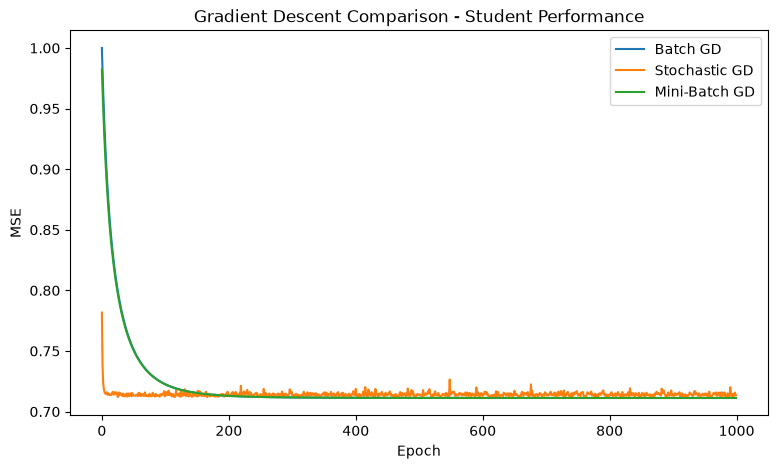

In [89]:
plt.figure(figsize=(9, 5))

plt.plot(cost_bgd4, label="Batch GD")
plt.plot(cost_sgd4, label="Stochastic GD")
plt.plot(cost_mbgd4, label="Mini-Batch GD")

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Gradient Descent Comparison - Student Performance")

plt.legend()
plt.show()

In [90]:
y_pred_bgd4 = X4_test @ weights_bgd4 + bias_bgd4
y_pred_sgd4 = X4_test @ weights_sgd4 + bias_sgd4
y_pred_mbgd4 = X4_test @ weights_mbgd4 + bias_mbgd4

mse_bgd4 = mse(y4_test_scaled, y_pred_bgd4)
mse_sgd4 = mse(y4_test_scaled, y_pred_sgd4)
mse_mbgd4 = mse(y4_test_scaled, y_pred_mbgd4)

print("Test MSE - Student Performance Dataset")
print("Batch GD:", mse_bgd4)
print("Stochastic GD:", mse_sgd4)
print("Mini-Batch GD:", mse_mbgd4)

Test MSE - Student Performance Dataset
Batch GD: 0.8382640398149379
Stochastic GD: 0.8273570184145717
Mini-Batch GD: 0.8378209285022282


In [91]:
results4 = {
    "Batch GD": mse_bgd4,
    "Stochastic GD": mse_sgd4,
    "Mini-Batch GD": mse_mbgd4
}

best_method4 = min(results4, key=results4.get)

print("Best Gradient Descent method:", best_method4)
print("Lowest Test MSE:", results4[best_method4])

Best Gradient Descent method: Stochastic GD
Lowest Test MSE: 0.8273570184145717


In [92]:
X_contour4 = df4[["studytime", "absences"]].values
y_contour4 = df4["G3"].values

print("Contour features shape:", X_contour4.shape)
print("Target shape:", y_contour4.shape)

Contour features shape: (395, 2)
Target shape: (395,)


In [93]:
x_scaler4 = StandardScaler()
y_scaler_contour4 = StandardScaler()

X_contour4 = x_scaler4.fit_transform(X_contour4)

y_contour4 = y_scaler_contour4.fit_transform(
    y_contour4.reshape(-1, 1)
).ravel()

In [94]:
def contour_cost4(w1, w2, bias):
    predictions = (
        w1 * X_contour4[:, 0]
        + w2 * X_contour4[:, 1]
        + bias
    )

    return np.mean((predictions - y_contour4) ** 2)

In [95]:
w1_values = np.linspace(-2, 2, 100)
w2_values = np.linspace(-2, 2, 100)

W1, W2 = np.meshgrid(w1_values, w2_values)

Z = np.zeros(W1.shape)

for i in range(W1.shape[0]):
    for j in range(W1.shape[1]):
        Z[i, j] = contour_cost4(
            W1[i, j],
            W2[i, j],
            0
        )

print("Cost surface created.")

Cost surface created.


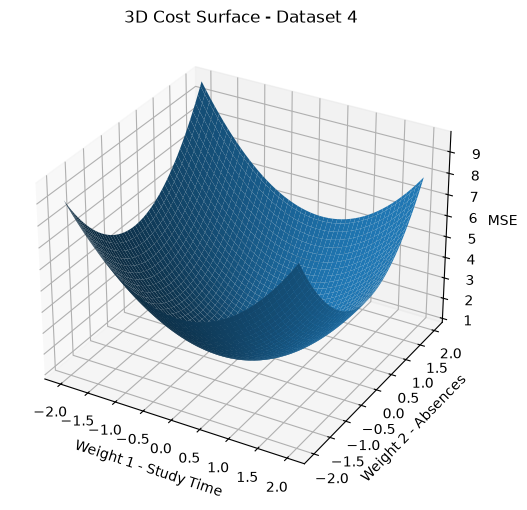

In [96]:
fig = plt.figure(figsize=(9, 6))

ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(W1, W2, Z)

ax.set_xlabel("Weight 1 - Study Time")
ax.set_ylabel("Weight 2 - Absences")
ax.set_zlabel("MSE")

ax.set_title("3D Cost Surface - Dataset 4")

plt.show()

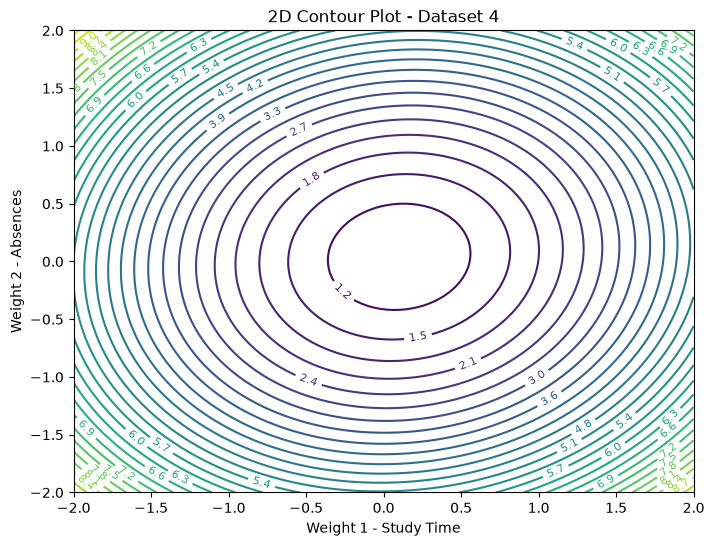

In [97]:
plt.figure(figsize=(8, 6))

contour = plt.contour(W1, W2, Z, levels=30)

plt.clabel(contour, inline=True, fontsize=8)

plt.xlabel("Weight 1 - Study Time")
plt.ylabel("Weight 2 - Absences")

plt.title("2D Contour Plot - Dataset 4")

plt.show()

FOR DATASET 5

In [98]:
df5 = pd.read_csv("Advertising Budget and Sales.csv")

print(df5.head())

print("\nShape:")
print(df5.shape)

print("\nColumns:")
print(df5.columns.tolist())

print("\nMissing values:")
print(df5.isnull().sum())

   Unnamed: 0  TV Ad Budget ($)  Radio Ad Budget ($)  Newspaper Ad Budget ($)  \
0           1             230.1                 37.8                     69.2   
1           2              44.5                 39.3                     45.1   
2           3              17.2                 45.9                     69.3   
3           4             151.5                 41.3                     58.5   
4           5             180.8                 10.8                     58.4   

   Sales ($)  
0       22.1  
1       10.4  
2        9.3  
3       18.5  
4       12.9  

Shape:
(200, 5)

Columns:
['Unnamed: 0', 'TV Ad Budget ($)', 'Radio Ad Budget ($)', 'Newspaper Ad Budget ($)', 'Sales ($)']

Missing values:
Unnamed: 0                 0
TV Ad Budget ($)           0
Radio Ad Budget ($)        0
Newspaper Ad Budget ($)    0
Sales ($)                  0
dtype: int64


In [99]:
X5 = df5.drop(["Sales ($)", "Unnamed: 0"], axis=1)
y5 = df5["Sales ($)"]

print("Features shape:", X5.shape)
print("Target shape:", y5.shape)

Features shape: (200, 3)
Target shape: (200,)


In [100]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X5_train, X5_test, y5_train, y5_test = train_test_split(
    X5.values,
    y5.values,
    test_size=0.2,
    random_state=42
)

scaler5 = StandardScaler()

X5_train = scaler5.fit_transform(X5_train)
X5_test = scaler5.transform(X5_test)

y5_scaler = StandardScaler()

y5_train_scaled = y5_scaler.fit_transform(
    y5_train.reshape(-1, 1)
).ravel()

y5_test_scaled = y5_scaler.transform(
    y5_test.reshape(-1, 1)
).ravel()

print("Training data:", X5_train.shape)
print("Testing data:", X5_test.shape)

Training data: (160, 3)
Testing data: (40, 3)


In [101]:
weights_bgd5, bias_bgd5, cost_bgd5 = batch_gradient_descent(
    X5_train,
    y5_train_scaled,
    learning_rate=0.01,
    epochs=1000
)

print("Batch GD Final MSE:", cost_bgd5[-1])

Batch GD Final MSE: 0.10429917289971473


In [102]:
weights_mbgd5, bias_mbgd5, cost_mbgd5 = mini_batch_gradient_descent(
    X5_train,
    y5_train_scaled,
    learning_rate=0.01,
    epochs=1000,
    batch_size=32
)

print("Mini-Batch GD Final MSE:", cost_mbgd5[-1])

Mini-Batch GD Final MSE: 0.10429926772672413


In [103]:
weights_sgd5, bias_sgd5, cost_sgd5 = stochastic_gradient_descent(
    X5_train,
    y5_train_scaled,
    learning_rate=0.01,
    epochs=1000
)

print("Stochastic GD Final MSE:", cost_sgd5[-1])

Stochastic GD Final MSE: 0.1120851080717358


In [104]:
y_pred_bgd5 = X5_test @ weights_bgd5 + bias_bgd5
y_pred_sgd5 = X5_test @ weights_sgd5 + bias_sgd5
y_pred_mbgd5 = X5_test @ weights_mbgd5 + bias_mbgd5

mse_bgd5 = mse(y5_test_scaled, y_pred_bgd5)
mse_sgd5 = mse(y5_test_scaled, y_pred_sgd5)
mse_mbgd5 = mse(y5_test_scaled, y_pred_mbgd5)

print("Test MSE - Advertising Dataset")
print("Batch GD:", mse_bgd5)
print("Stochastic GD:", mse_sgd5)
print("Mini-Batch GD:", mse_mbgd5)

Test MSE - Advertising Dataset
Batch GD: 0.12238083081316212
Stochastic GD: 0.11803347794843341
Mini-Batch GD: 0.12243216438627265


In [105]:
results5 = {
    "Batch GD": mse_bgd5,
    "Stochastic GD": mse_sgd5,
    "Mini-Batch GD": mse_mbgd5
}

best_method5 = min(results5, key=results5.get)

print("Best Gradient Descent method:", best_method5)
print("Lowest Test MSE:", results5[best_method5])

Best Gradient Descent method: Stochastic GD
Lowest Test MSE: 0.11803347794843341


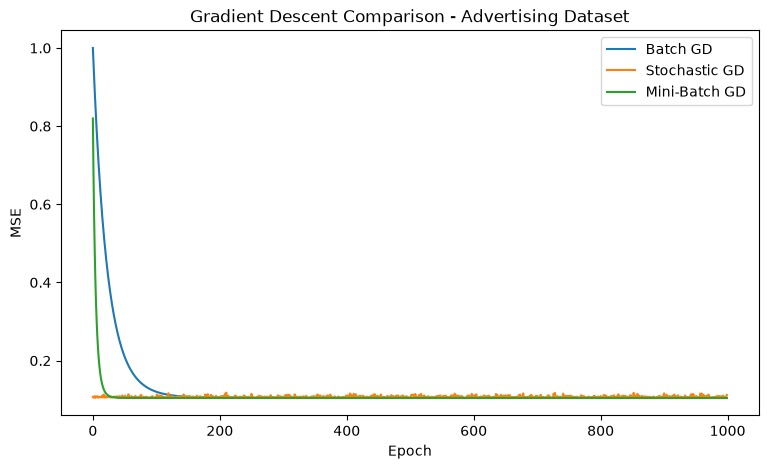

In [106]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(cost_bgd5, label="Batch GD")
plt.plot(cost_sgd5, label="Stochastic GD")
plt.plot(cost_mbgd5, label="Mini-Batch GD")

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Gradient Descent Comparison - Advertising Dataset")
plt.legend()

plt.show()

In [107]:
X_contour5 = X5_train[:, :2]
y_contour5 = y5_train_scaled

w1 = weights_bgd5[0]
w2 = weights_bgd5[1]

b = bias_bgd5
w3 = weights_bgd5[2]

x1 = np.linspace(X_contour5[:, 0].min(), X_contour5[:, 0].max(), 50)
x2 = np.linspace(X_contour5[:, 1].min(), X_contour5[:, 1].max(), 50)

W1, W2 = np.meshgrid(x1, x2)

Z = np.zeros(W1.shape)

for i in range(W1.shape[0]):
    for j in range(W1.shape[1]):
        prediction = W1[i, j] * w1 + W2[i, j] * w2 + b
        prediction = prediction + w3 * 0
        Z[i, j] = np.mean((prediction - y_contour5.mean()) ** 2)

print("Contour data prepared.")

Contour data prepared.


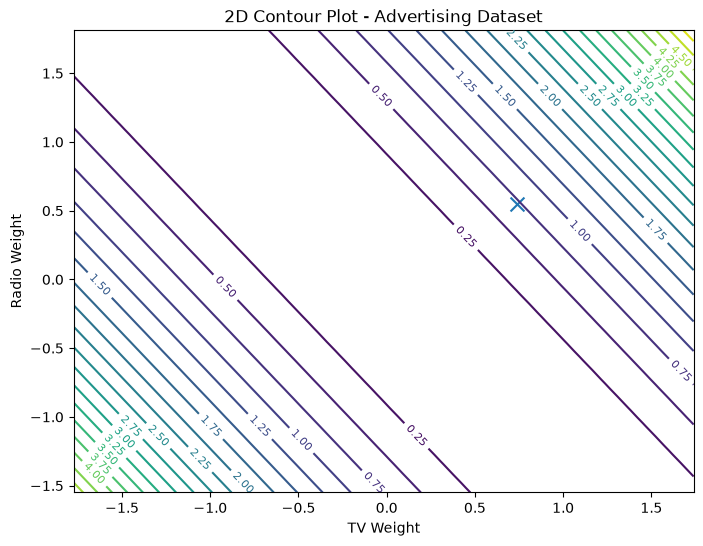

In [108]:
plt.figure(figsize=(8, 6))

contour = plt.contour(W1, W2, Z, levels=20)

plt.clabel(contour, inline=True, fontsize=8)

plt.scatter(w1, w2, marker="x", s=100)

plt.xlabel("TV Weight")
plt.ylabel("Radio Weight")
plt.title("2D Contour Plot - Advertising Dataset")

plt.show()

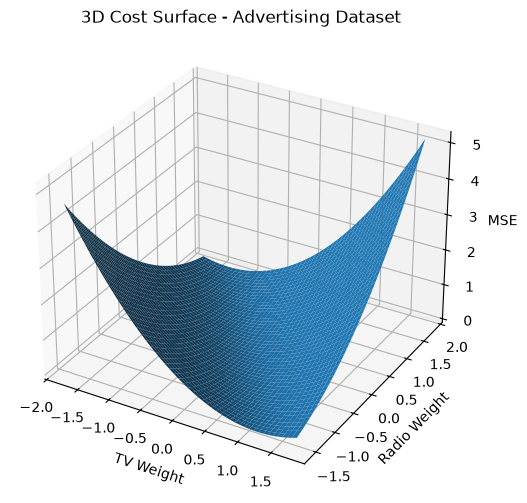

In [109]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(9, 6))

ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(W1, W2, Z)

ax.set_xlabel("TV Weight")
ax.set_ylabel("Radio Weight")
ax.set_zlabel("MSE")

ax.set_title("3D Cost Surface - Advertising Dataset")

plt.show()

In [110]:
print("===== Dataset 5 Results =====")
print("Batch GD Test MSE:", mse_bgd5)
print("Stochastic GD Test MSE:", mse_sgd5)
print("Mini-Batch GD Test MSE:", mse_mbgd5)
print("Best Method:", best_method5)

===== Dataset 5 Results =====
Batch GD Test MSE: 0.12238083081316212
Stochastic GD Test MSE: 0.11803347794843341
Mini-Batch GD Test MSE: 0.12243216438627265
Best Method: Stochastic GD
